In [63]:
import pandas as pd
import matplotlib
from matplotlib import cm
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('ggplot')

In [64]:
model_names = ['bert', 'elmo', 'gpt2', 'nnlm', 'reformer', 'use', 'word2vec', 'xlm', 'gpt']
scores = pd.DataFrame(columns=['method', 'metric', 'score'])
times = pd.DataFrame(columns=['model', 'time'])

for model_name in model_names:
    times = times.append(pd.read_csv('Scores/{}_times.csv'.format(model_name), index_col=None))
    scores = scores.append(pd.read_csv('Scores/{}_scores.csv'.format(model_name), index_col=None))


In [106]:
scores = scores.drop_duplicates()
scores = scores[['method', 'metric', 'score']]
scores = scores.sort_values(['method'])

In [107]:
distance_metrics = np.unique(scores['metric'])

No handles with labels found to put in legend.


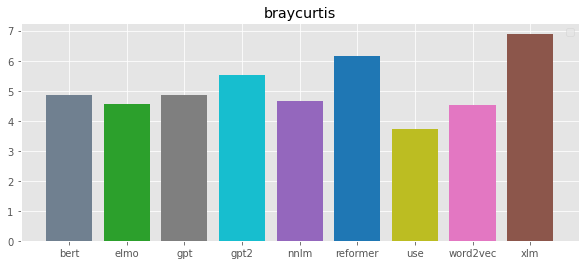

No handles with labels found to put in legend.


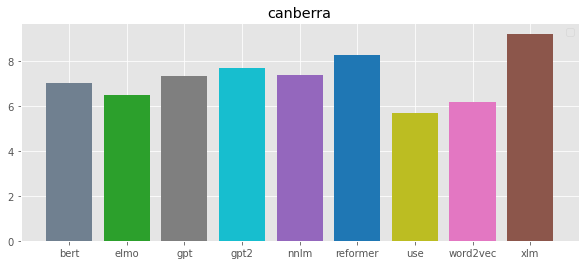

No handles with labels found to put in legend.


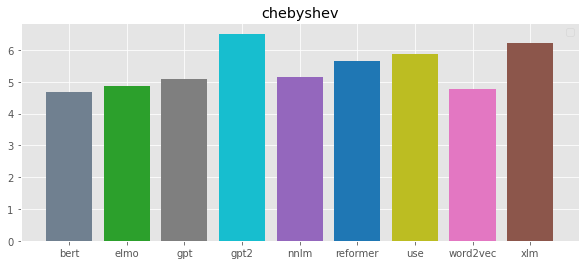

No handles with labels found to put in legend.


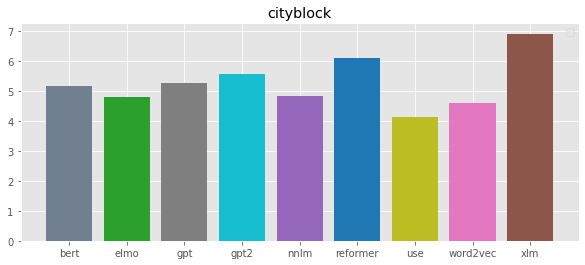

No handles with labels found to put in legend.


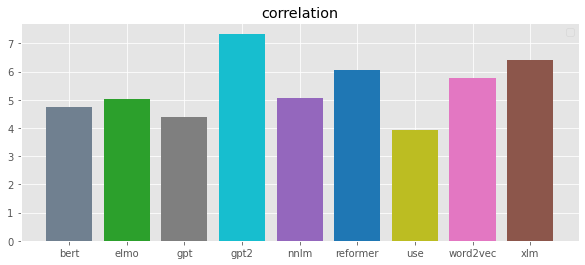

No handles with labels found to put in legend.


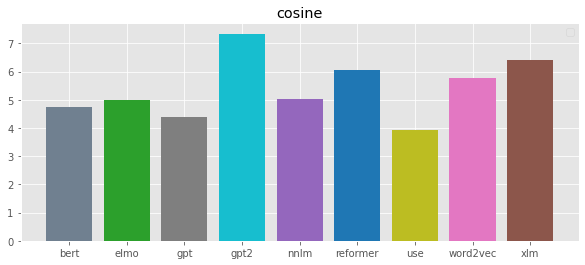

No handles with labels found to put in legend.


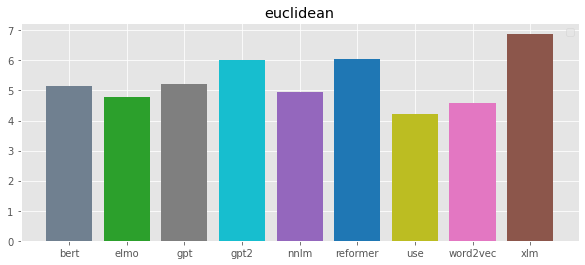

No handles with labels found to put in legend.


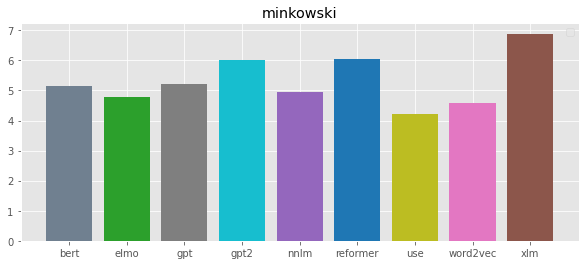

No handles with labels found to put in legend.


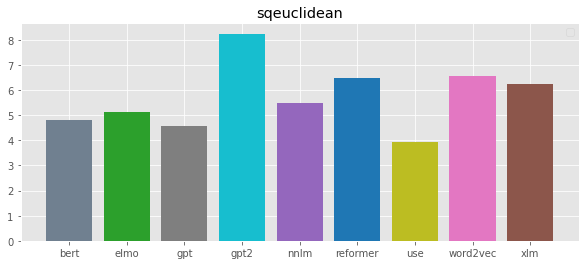

In [112]:
from matplotlib.colors import Normalize
from random import shuffle 
from random import seed 

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'teal', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan', 'slategray']
seed(4)
shuffle(colors)

for distance_metric in distance_metrics:
  fig, ax = plt.subplots(figsize=(10,4))
  grp =  scores[scores.metric == distance_metric]
  ax.bar(grp['method'], grp['score'], color=colors[:len(model_names)])
  plt.title(distance_metric)

  ax.legend()
  plt.show()

In [142]:
sorted_scores = scores.sort_values(['score']).groupby('method').first()
sorted_scores = sorted_scores.reset_index()
sorted_scores = sorted_scores.sort_values(['score'])
sorted_scores['score'] = minmax_scale(sorted_scores['score'], feature_range=(0.01,1))

No handles with labels found to put in legend.


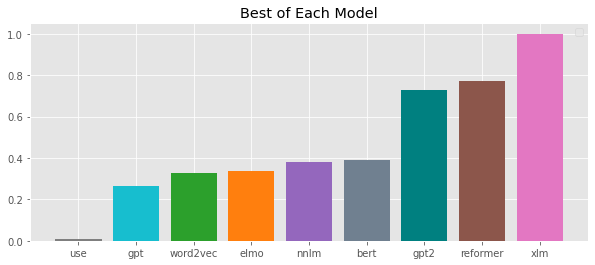

In [143]:
shuffle(colors)
fig, ax = plt.subplots(figsize=(10,4))
grp =  sorted_scores
ax.bar(grp['method'], grp['score'], color=colors[:len(model_names)])
plt.title('Best Performance of Each Model ')

ax.legend()
plt.show()

In [140]:
from sklearn.preprocessing import minmax_scale

times = times[['model', 'time']]
times = times.drop_duplicates()
times = times.sort_values(['time'])
norm_times = times
norm_times['time'] = minmax_scale(norm_times['time'], feature_range=(0.01,1))

No handles with labels found to put in legend.


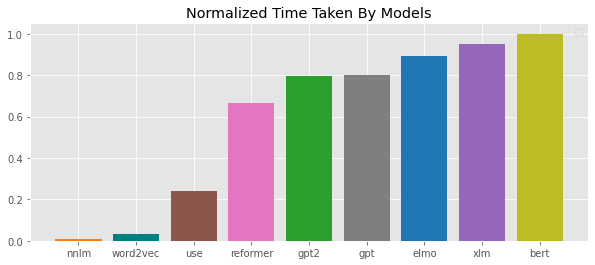

In [141]:
fig, ax = plt.subplots(figsize=(10,4))
grp =  norm_times
ax.bar(grp['model'], grp['time'], color=colors[:len(model_names)])
plt.title('Normalized Time Taken By Models')

ax.legend()
plt.show()